# [Lab Session 3](fourier.ipynb)


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from skimage.transform import resize

**[Task 1 (a).]()** Load the first image, resize it to (256, 256) and display it.


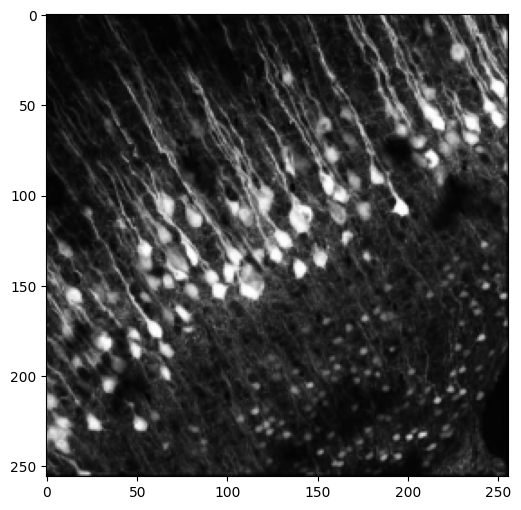

In [3]:
cell_img = plt.imread('data/cells.png')
cell_img = resize(cell_img, (256, 256))

plt.figure(figsize=(6, 6))
plt.imshow(cell_img, cmap='gray')
plt.show()

**[Task 1 (b).]()** Apply the fast Fourier transform and check the data type of the result.


In [9]:
cell_ft = np.fft.fft2(cell_img)
cell_ft.dtype

dtype('complex128')

**[Task 1 (c).]()** Extract the phase and amplitude and display them.


In [5]:
amplitude = np.abs(cell_ft)
phase = np.angle(cell_ft)

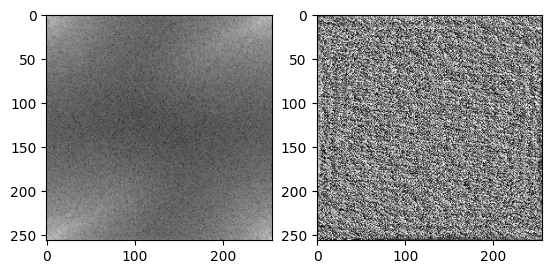

In [6]:
plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(amplitude), 'gray')
plt.subplot(1, 2, 2)
plt.imshow(phase, 'gray')

**[Task 1 (d).]()** Do a shift so that zero is displayed in the center of the image and show amplitude and phase again.


Note for self: shifted it with the command given in the assignments part -->
changed the amplitude and phase accordingly -->
showed it in the same way 

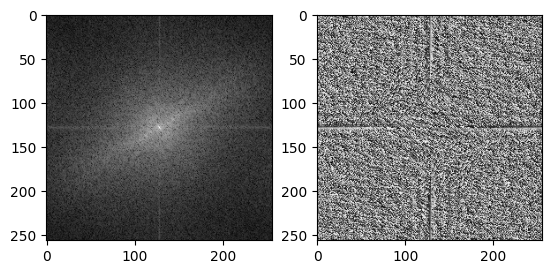

In [7]:
shifted = np.fft.fftshift(cell_ft)

amplitude_shifted = np.abs(shifted)
phase_shifted = np.angle(shifted)

plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log1p(amplitude_shifted), cmap='gray')

plt.subplot(1, 2, 2)
plt.imshow(phase_shifted, cmap='gray')
plt.show()

**[Task 1 (e).]()** Apply the inverse FFT and display the restored image.


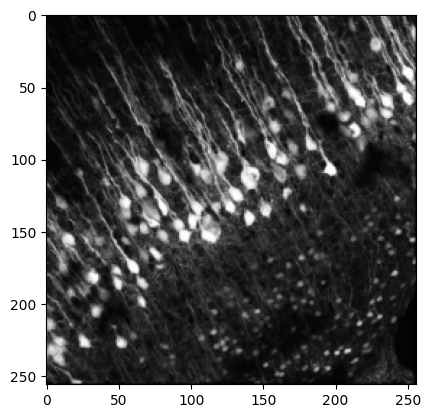

In [11]:
restored = np.fft.ifft2(np.fft.ifftshift(shifted))
plt.figure()
plt.imshow(restored.real, cmap='gray')
plt.show()

---


**[Task 2 (a).]()** Load the brain MR image.


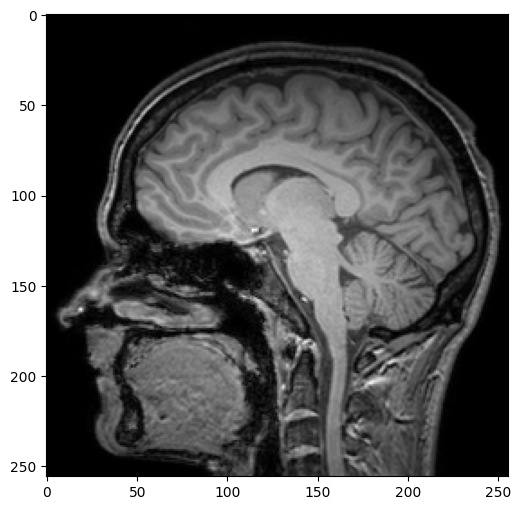

In [12]:
brain = plt.imread('data/brain_mri.png')
plt.figure(figsize=(6, 6))
plt.imshow(brain, cmap='gray')
plt.show()


**[Task 2 (b).]()** Apply the FFT, do a shift, extract amplitude and phase.


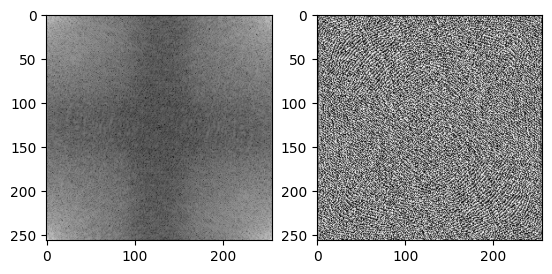

In [16]:
brain_ft = np.fft.fft2(brain)

amplitude = np.abs(brain_ft)
phase = np.angle(brain_ft)

shifted_brain = np.fft.fftshift(brain_ft)

amplitude_shifted_brain = np.abs(shifted_brain)
phase_shifted_brain = np.angle(shifted_brain)

plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(amplitude), 'gray')
plt.subplot(1, 2, 2)
plt.imshow(phase, 'gray')

In [17]:
def to_complex_array(amplitude_array, phase_array):
    return amplitude_array * np.exp(1j * phase_array)

**[Task 2 (c).]()** Merge the amplitude of the brain MR image and the phase of cell image. Do the IFFT and display the resulting image.


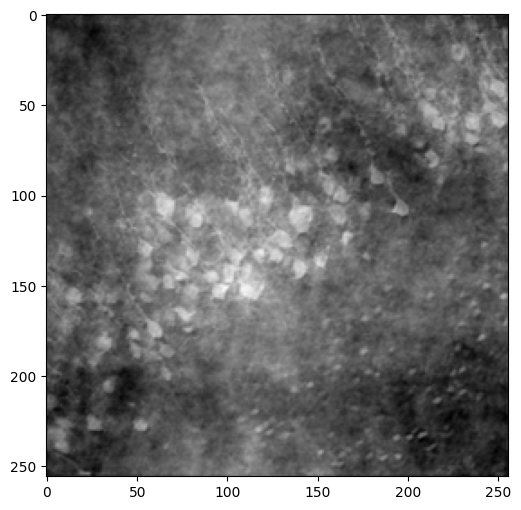

In [18]:
brain_amplitude = np.abs(brain_ft)
cell_phase = np.angle(cell_ft)

merged_ft = to_complex_array(brain_amplitude, cell_phase)
merged_img = np.fft.ifft2(merged_ft).real

plt.figure(figsize=(6, 6))
plt.imshow(merged_img, cmap='gray')
plt.show()

**[Task 2 (d).]()** Repeat this with the amplitude of the cells and the phase of the brain.


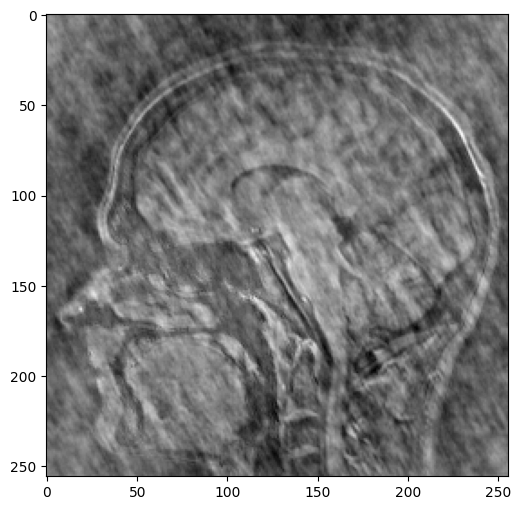

In [20]:
brain_phase = np.angle(brain_ft)
cell_amplitude = np.abs(cell_ft)

merged_ft = to_complex_array(cell_amplitude, brain_phase)
merged_img = np.fft.ifft2(merged_ft).real

plt.figure(figsize=(6, 6))
plt.imshow(merged_img, cmap='gray')
plt.show()

the phase carries more info

---


**[Task 3 (a).]()** Create a lowpass filter mask.


In [ ]:
filter_window_size = 50

**[Task 3 (b).]()** Create a highpass filter maks.


**[Task 3 (c).]()** Apply the lowpass and highpass filter mask to the amplitude of the brain and display the results.


**[Task 3 (d).]()** Apply the mask to the amplitude, merge the result with the phase and restore the image.


---


**[Task 4 (a).]()** Implement a function that computes the 2D-DFT.


**[Task 4 (b).]()** Implement a function that computes the 2D-IDFT.


Due to high computational costs, we need to resize the image.


In [ ]:
test_img = resize(brain_img, (40, 40))
plt.imshow(test_img, 'gray')

**[Task 4 (c).]()** Apply your DFT implementation to the image and display amplitude and phase.


**[Task 4 (d).]()** Reconstruct the image using your IDFT implementation and display it.


**[Task 4 (e).]()** Compare your result to the result of numpy's FFT


**[Task 4 (f).]()** Round the arrays and compare them again.


**[Task 4 (g).]()** Compare the run times of the two algorithms (your DFT and numpy's FFT)
